## Examen 2 | Modelo de Varianza: GARCH — GMEXICOB
Aplicamos el modelo Generalizado Autorregresivo de Heterocedasticidad Condicional (GARCH) al precio de Grupo México
(GMEXICOB), usando los últimos 2 años de datos. 
Probaremos 4 configuraciones distintas de rezagos (p,q): (1,1), (1,2), (2,1) y (2,2) para encontrar cuál pronostica mejor.

### El modelo

El modelo GARCH(p,q) asume que la varianza condicional de hoy depende tanto de los
rendimientos al cuadrado pasados (efecto ARCH) como de las varianzas estimadas pasadas (efecto GARCH):

$$\sigma^2_t = \omega + \sum_{i=1}^{q} \alpha_i R^2_{t-i} + \sum_{j=1}^{p} \beta_j \sigma^2_{t-j}$$

- $t$: día para el que estimamos la varianza.
- $q$: número de rezagos de los rendimientos al cuadrado (términos ARCH).
- $p$: número de rezagos de la varianza condicional (términos GARCH).
- $\omega$: constante del modelo ($\omega > 0$).
- $\alpha_i, \beta_j$: coeficientes de impacto ($\alpha_i \ge 0$, $\beta_j \ge 0$).

La volatilidad es la raíz de la varianza: $\sigma_t = \sqrt{\sigma^2_t}$

In [13]:
import sys, os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

SRC_PATH = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.append(SRC_PATH)

from calculo_rendimientos import calculate_returns

GMEXICO_PATH = os.path.join("..", "datos_historicos", "gmexico_prices.csv")

### Datos: últimos 2 años de GMEXICOB

Reutilizamos `calculate_returns()` y filtramos a los últimos 2
años, manteniendo la base idéntica a la utilizada en Media Móvil y EWMA.

In [14]:
# carga y filtros 
df_gmexico = calculate_returns(GMEXICO_PATH)

fecha_fin = df_gmexico.index.max()
fecha_inicio = fecha_fin - pd.DateOffset(years=2)
df_2y = df_gmexico.loc[fecha_inicio:].copy()

print(f"Periodo: {df_2y.index.min().date()} a {df_2y.index.max().date()}")
print(f"Total de dias habiles: {len(df_2y)}")
df_2y.tail()

Periodo: 2024-09-17 a 2026-09-14
Total de dias habiles: 499


,adj_close,simple_return,log_return,cumulative_return
Date,,,,
2026-09-08,229.559998,0.025875,0.025546,116.658060
2026-09-09,228.500000,-0.004618,-0.004628,116.119389
2026-09-10,218.339996,-0.044464,-0.045483,110.956267
2026-09-11,218.300003,-0.000183,-0.000183,110.935943
2026-09-14,213.910004,-0.020110,-0.020315,108.705029


### $R^2$: nuestro proxy de la varianza "real" de cada día

Como en los modelos anteriores, usamos el retorno logarítmico al cuadrado
($R^2$) como nuestra varianza observada contra la cual mediremos el error de los modelos GARCH.

In [15]:
r = df_2y['log_return']
r2 = r**2
r2.tail()

Date
2026-09-08    6.525810e-04
2026-09-09    2.142035e-05
2026-09-10    2.068680e-03
2026-09-11    3.355731e-08
2026-09-14    4.126949e-04
Name: log_return, dtype: float64

### Estimación de la Varianza Condicional GARCH por configuración

Ajustamos el modelo GARCH para distintas combinaciones de $(p,q)$.

*Nota metodológica:* Para optimizar correctamente los parámetros de máxima verosimilitud en `arch_model`, multiplicamos los retornos por 100 (cambio de escala a porcentaje). Al extraer la varianza, dividimos entre $100^2 = 10,000$ para regresar a la escala original.

In [16]:
# Configuraciones a probar: (p, q)
garch_orders = [(1,1), (1,2), (2,1), (2,2)]
sigma2_garch = pd.DataFrame(index=r.index)

# Escalamiento para la convergencia del optimizador
r_pct = r * 100

for p, q in garch_orders:
    # Definimos y ajustamos el modelo GARCH(p,q)
    am = arch_model(r_pct, vol='GARCH', p=p, q=q, mean='Zero', dist='Normal')
    res = am.fit(disp='off')
    
    # Obtenemos la varianza condicional in-sample y regresamos a la escala original
    sigma2_garch[f'var_p{p}_q{q}'] = res.conditional_volatility**2 / 10000

sigma2_garch.tail()

,var_p1_q1,var_p1_q2,var_p2_q1,var_p2_q2
Date,,,,
2026-09-08,0.000437,0.000421,0.000437,0.000421
2026-09-09,0.000462,0.000492,0.000462,0.000492
2026-09-10,0.000430,0.000383,0.000430,0.000383
2026-09-11,0.000575,0.000688,0.000575,0.000688
2026-09-14,0.000525,0.000350,0.000525,0.000350


### RMSE: ¿cuál modelo GARCH ajusta mejor?

Comparamos cada estimación de varianza condicional $\sigma^2_{t}$ de los modelos GARCH contra el $R^2_t$ real.
**La combinación $(p,q)$ con menor RMSE será nuestro modelo óptimo.**

In [17]:
sigma2_rmse = sigma2_garch.dropna()
r2_rmse = r2.loc[sigma2_rmse.index]

rmse = pd.Series(dtype=float)
for p, q in garch_orders:
    col_name = f'var_p{p}_q{q}'
    rmse[col_name] = np.sqrt((1/len(r2_rmse)) * ((r2_rmse - sigma2_rmse[col_name])**2).sum())

rmse

var_p1_q1    0.001412
var_p1_q2    0.001412
var_p2_q1    0.001412
var_p2_q2    0.001412
dtype: float64

In [18]:
# Extraemos el mejor p y q del nombre del índice con menor RMSE
best_model_name = rmse.idxmin()
p_opt = int(best_model_name.split('_')[1].replace('p', ''))
q_opt = int(best_model_name.split('_')[2].replace('q', ''))

print(f"Modelo óptimo GARCH (menor RMSE): GARCH({p_opt}, {q_opt})")
rmse

Modelo óptimo GARCH (menor RMSE): GARCH(1, 2)


var_p1_q1    0.001412
var_p1_q2    0.001412
var_p2_q1    0.001412
var_p2_q2    0.001412
dtype: float64

### Pronóstico de volatilidad para mañana

Usando el modelo GARCH ganador, generamos el pronóstico analítico de la varianza
para mañana ($T+1$) utilizando la función `.forecast()` de la librería.

Para anualizar: $\sigma_{\text{anual}} = \sqrt{252\,\sigma^2_{T+1}}$

In [19]:
# Reajustamos el modelo con el p y q óptimos para extraer el pronóstico fácilmente
am_opt = arch_model(r_pct, vol='GARCH', p=p_opt, q=q_opt, mean='Zero', dist='Normal')
res_opt = am_opt.fit(disp='off')

# Pronóstico de varianza a 1 paso (mañana)
forecast = res_opt.forecast(horizon=1)

# Extraemos el último valor pronosticado y devolvemos a escala original
var_manana = forecast.variance.iloc[-1, 0] / 10000
vol_anual_manana = np.sqrt(252 * var_manana)

print(f"Varianza pronosticada para manana (GARCH({p_opt},{q_opt})): {var_manana:.6f}")
print(f"Volatilidad anualizada pronosticada: {vol_anual_manana:.2%}")

Varianza pronosticada para manana (GARCH(1,2)): 0.000640
Volatilidad anualizada pronosticada: 40.16%


### Gráfica: volatilidad condicional anualizada por modelo GARCH (Separadas)

Visualizamos de forma individual cómo ajusta cada configuración de GARCH la volatilidad condicional en el tiempo, fijando el eje Y desde 0.2 para mayor claridad.

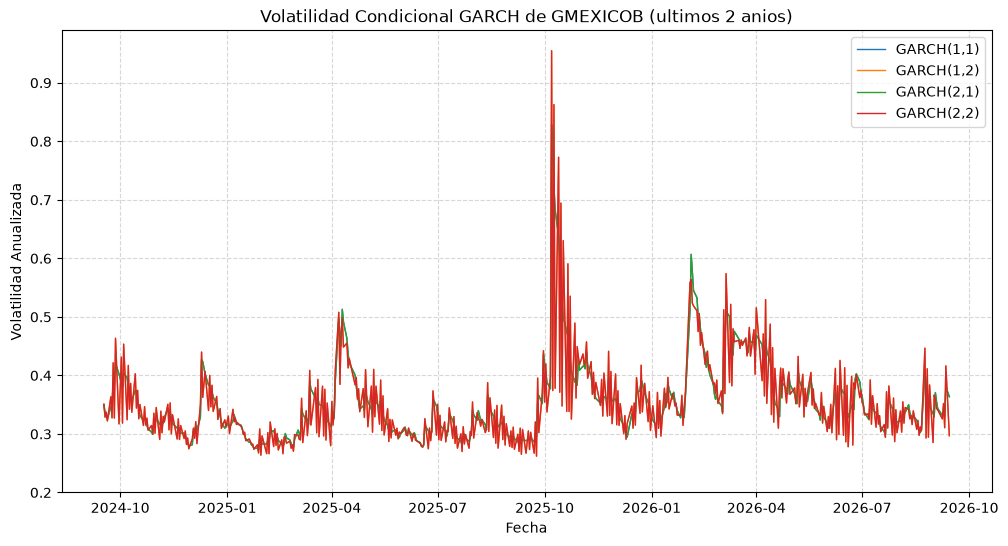

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

for p, q in garch_orders:
    col_name = f'var_p{p}_q{q}'
    vol_anual = np.sqrt(sigma2_garch[col_name] * 252)
    ax.plot(sigma2_garch.index, vol_anual, label=f'GARCH({p},{q})', linewidth=1)

# Fijar el límite inferior del eje Y en 0.2 para evitar que los picos aplasten la gráfica
ax.set_ylim(bottom=0.2)

ax.set_xlabel('Fecha')
ax.set_ylabel('Volatilidad Anualizada')
ax.set_title('Volatilidad Condicional GARCH de GMEXICOB (ultimos 2 anios)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

save_path = os.path.join("..", "graficas", "garch_volatilidad.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()